# Dimensionality Reduction

Practical revision notebook:

**Basic workflow → major methods → compare → model improvement**

Dimensionality reduction reduces the number of features while trying to preserve useful information or structure.

Main uses:
- Reduce many features
- Remove redundancy/noise
- Speed up models
- Visualize high-dimensional data

## Basic Workflow

1. Load dataset
2. EDA
3. Preprocessing
4. Select features
5. Scale features
6. Apply dimensionality reduction
7. Check information/structure retained
8. Transform data
9. Visualize
10. Compare methods
11. Improve

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/raw/winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [64]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [65]:
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

Shape: (1599, 12)

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicates: 240


### Preprocessing

Typical steps:
- Handle missing values
- Encode categorical variables if needed
- Select useful features
- Scale numerical features

Scaling is especially important for PCA, LDA, t-SNE and UMAP when features use different units.

In [66]:
# since PCA, t-SNE, and UMAP only work on numbers

df_clean = df.dropna().drop_duplicates().copy()
print(df_clean.shape)


(1359, 12)


In [67]:
# Separate features (X) and target (y)

X = df_clean.drop("quality", axis=1).select_dtypes(include=np.number)
y = df_clean["quality"]

In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled.shape

(1359, 11)

# PCA

**Use:** General-purpose linear dimensionality reduction; reduce features while preserving as much variance as possible.

Main parameter:
- `n_components` → number of components to keep

In [69]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)

print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Original shape: (1359, 11)
Reduced shape: (1359, 2)
Explained variance: [0.28293989 0.17347505]
Total explained variance: 0.45641493888586104


In [70]:
# See which original features make up PC1 and PC2

loadings = pd.DataFrame(
    pca.components_.T, 
    columns=["PC1", "PC2"], 
    index=X.columns
)
print("\nFeature Loadings:\n", loadings.round(3))


Feature Loadings:
                         PC1    PC2
fixed acidity         0.485 -0.111
volatile acidity     -0.239  0.276
citric acid           0.463 -0.155
residual sugar        0.134  0.238
chlorides             0.214  0.131
free sulfur dioxide  -0.023  0.512
total sulfur dioxide  0.036  0.576
density               0.392  0.231
pH                   -0.444  0.002
sulphates             0.250 -0.055
alcohol              -0.118 -0.403


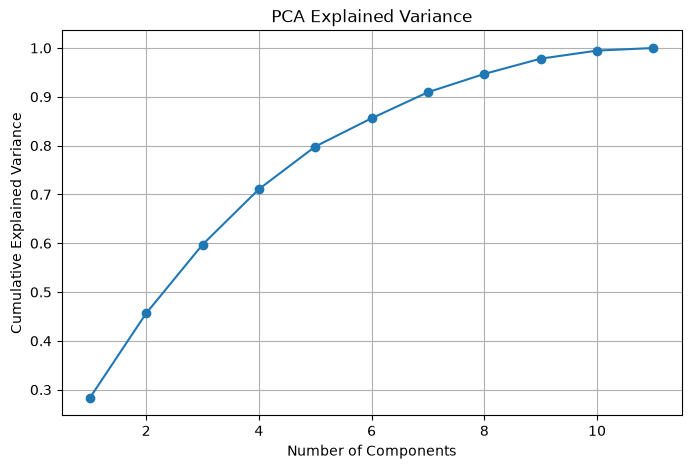

In [71]:
# Choose number of components using cumulative explained variance

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()

# LDA

**Use:** Supervised dimensionality reduction when class labels are available and you want to maximize class separation.

Unlike PCA, LDA uses `y`.

Main parameter:
- `n_components`

In [72]:
# Requires a classification dataset with a target column.

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_lda.shape)
print("Explained variance ratio:", lda.explained_variance_ratio_)
print("Total explained variance:", lda.explained_variance_ratio_.sum())

Original shape: (1359, 11)
Reduced shape: (1359, 2)
Explained variance ratio: [0.83994531 0.11142196]
Total explained variance: 0.9513672689979815


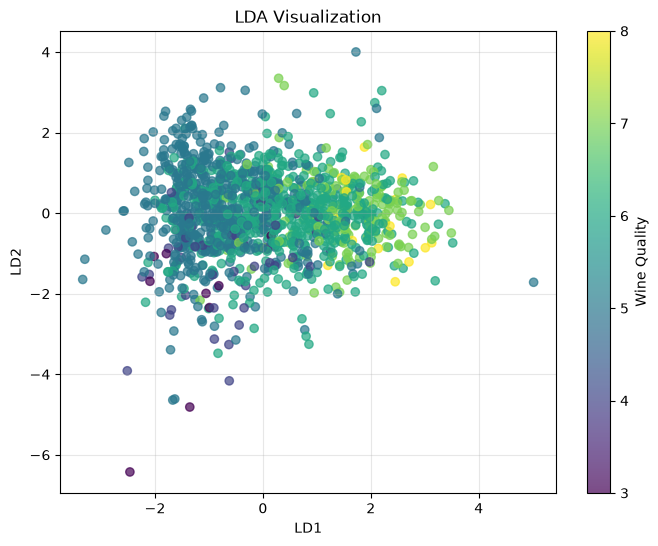

In [73]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Wine Quality")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA Visualization")
plt.grid(alpha=0.3)
plt.show()

# t-SNE

**Use:** Mainly for 2D/3D visualization of high-dimensional data, especially local neighborhoods.

Important parameters:
- `n_components`
- `perplexity`
- `learning_rate`
- `max_iter`

t-SNE is mainly a visualization method, not usually the first choice for general-purpose preprocessing.

In [74]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_tsne.shape)
print("KL divergence (lower = better local fit):", round(tsne.kl_divergence_, 4))

Original shape: (1359, 11)
Reduced shape: (1359, 2)
KL divergence (lower = better local fit): 1.1222


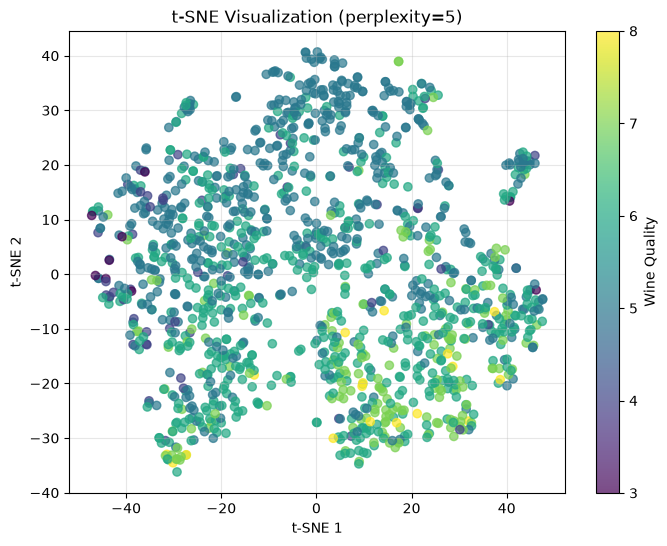

In [75]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Wine Quality")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE Visualization (perplexity=5)")
plt.grid(alpha=0.3)
plt.show()

# UMAP

**Use:** Non-linear dimensionality reduction for visualization and manifold learning; often a fast alternative to t-SNE.

Important parameters:
- `n_components`
- `n_neighbors`
- `min_dist`

Requires `umap-learn`.

In [76]:
!pip install umap-learn


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
import umap

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_umap.shape)

c:\Users\13ver\Desktop\New folder\prgm\ML\.MLvenv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\13ver\Desktop\New folder\prgm\ML\.MLvenv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original shape: (1359, 11)
Reduced shape: (1359, 2)


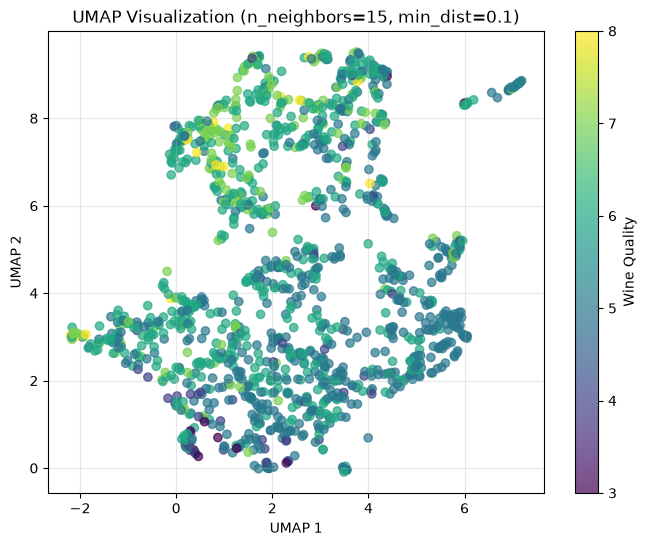

In [78]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Wine Quality")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP Visualization (n_neighbors=15, min_dist=0.1)")
plt.grid(alpha=0.3)
plt.show()

## Method Comparison

| Method | Supervised? | Main use | Linear? |
|---|---|---|---|
| PCA | No | Feature reduction / compression | Yes |
| LDA | Yes | Class separation | Yes |
| t-SNE | Usually no | Visualization | No |
| UMAP | Usually no | Visualization / manifold learning | No |

### Quick selection

**Need general feature reduction → PCA**

**Have class labels and want class separation → LDA**

**Need 2D/3D visualization → t-SNE or UMAP**

C:\Users\13ver\AppData\Local\Temp\ipykernel_21868\2590077319.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


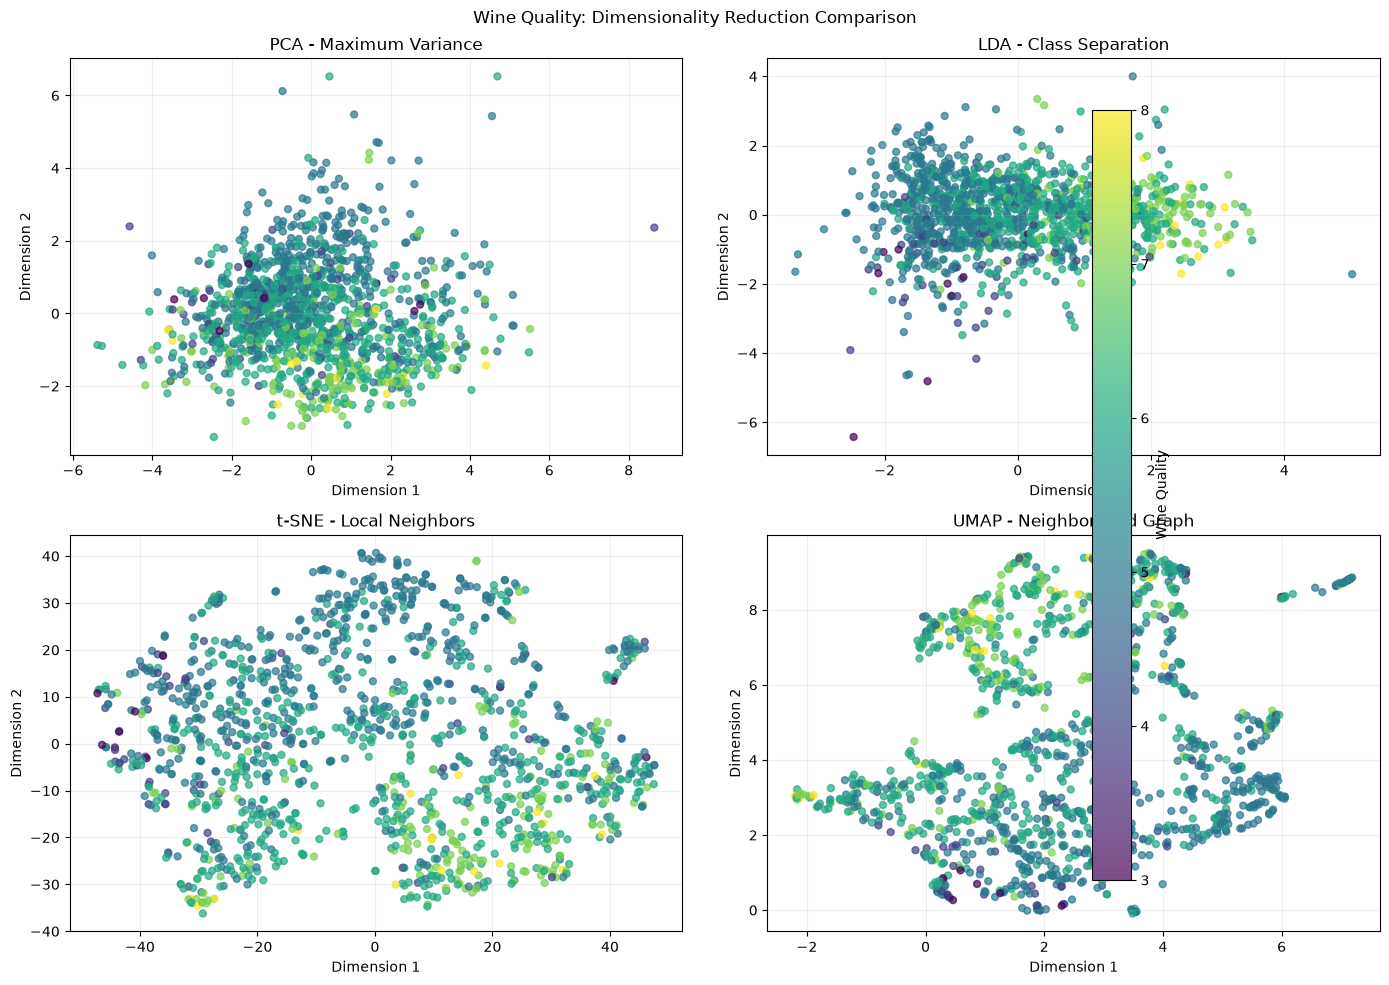

In [79]:
# Compare all four dimensionality reduction techniques

import matplotlib.pyplot as plt

methods = [
    (X_pca, "PCA - Maximum Variance"),
    (X_lda, "LDA - Class Separation"),
    (X_tsne, "t-SNE - Local Neighbors"),
    (X_umap, "UMAP - Neighborhood Graph")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (data, name) in zip(axes.ravel(), methods):

    sc = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=y,
        cmap="viridis",
        alpha=0.7,
        s=25
    )

    ax.set_title(name)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.grid(alpha=0.2)

fig.colorbar(sc, ax=axes.ravel().tolist(),
             label="Wine Quality")

plt.suptitle("Wine Quality: Dimensionality Reduction Comparison")
plt.tight_layout()
plt.show()


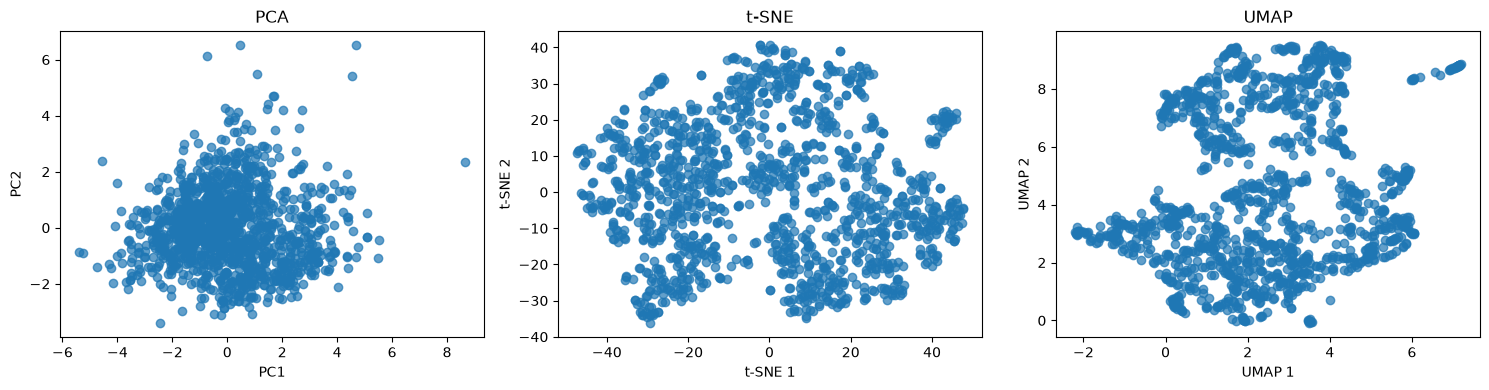

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

axes[0].scatter(X_pca[:,0], X_pca[:,1], alpha=0.7)
axes[0].set_title("PCA")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(X_tsne[:,0], X_tsne[:,1], alpha=0.7)
axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

axes[2].scatter(X_umap[:,0], X_umap[:,1], alpha=0.7)
axes[2].set_title("UMAP")
axes[2].set_xlabel("UMAP 1")
axes[2].set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()

## Model Improvement

**Baseline → Preprocess/Scale → Choose method → Tune components/parameters → Transform data → Check information retained → Evaluate downstream task**

### PCA
Tune:
- `n_components`

Check:
- Explained variance

### LDA
Tune:
- `n_components`

Check:
- Class separation
- Downstream classification performance

### t-SNE
Tune:
- `perplexity`
- `learning_rate`
- `max_iter`

Check:
- Visualization stability
- Local structure

### UMAP
Tune:
- `n_neighbors`
- `min_dist`
- `n_components`

Check:
- Local/global structure
- Visualization
- Downstream task performance

**Important:** A visually nice 2D plot does not automatically mean the representation is best for prediction.

## Quick Revision

**PCA** → linear + unsupervised + preserves variance

**LDA** → linear + supervised + separates classes

**t-SNE** → non-linear + mainly visualization + local neighborhoods

**UMAP** → non-linear + visualization/manifold learning

### Main difference

PCA → preserve variance

LDA → separate classes

t-SNE → preserve local neighborhoods for visualization

UMAP → preserve useful manifold structure in lower dimensions